# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Patrick Lee, Jason Zermani, Tesher Baer, Nathan Brence

**Date:** 11/11/2026

         sale_price  house_square_feet      bedrooms     bathrooms  \
count  1.679700e+04       16797.000000  16797.000000  16797.000000   
mean   4.609776e+05        1880.764363      3.280169      2.318390   
std    2.342215e+05         759.762716      0.888038      0.826711   
min    2.000000e+03           1.000000      0.000000      0.000000   
25%    3.480000e+05        1320.000000      3.000000      2.000000   
50%    4.163430e+05        1774.000000      3.000000      2.000000   
75%    5.235450e+05        2352.000000      4.000000      3.000000   
max    6.130000e+06        9510.000000     25.000000      8.000000   

            stories    year_built    fireplaces  
count  16797.000000  16797.000000  16797.000000  
mean       1.559028   1980.469012      0.889445  
std        0.511287     33.337722      0.596574  
min        0.000000   1880.000000      0.000000  
25%        1.000000   1959.000000      1.000000  
50%        2.000000   1990.000000      1.000000  
75%        2.000000

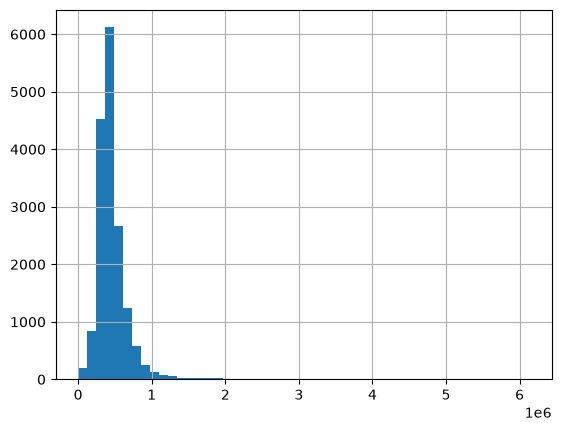

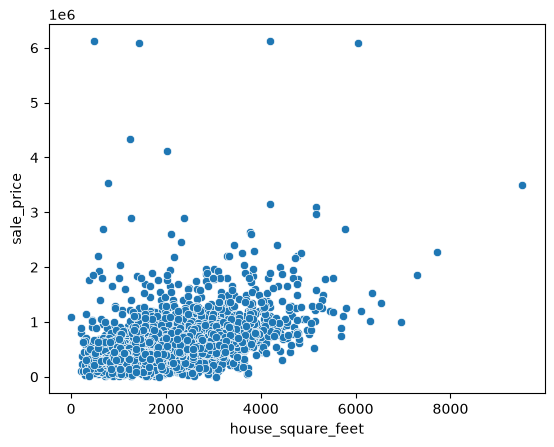

In [13]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/pierce_county_house_sales.csv")

numeric = ["house_square_feet", "bedrooms", "bathrooms", "stories", "year_built", "fireplaces"]
# the waterfront_type and view_quality columns are not considered, since they contain mostly null entries
categorical = ["exterior", "interior", "hvac_description", "roof_cover", "utility_sewer"]
features = numeric + categorical

df = df.dropna(subset=features + ["sale_price"]).copy()
df = df[df["sale_price"] > 0]

print(df[["sale_price"] + numeric].describe())
print(df["exterior"].value_counts())

df["sale_price"].hist(bins=50)
plt.show()

sns.scatterplot(data=df, x="house_square_feet", y="sale_price")
plt.show()

In [14]:
X = pd.get_dummies(df[features], drop_first=True, dtype=int)
y = df["sale_price"]

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=100
)

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# model 1: Use all numeric and categorical variables
model_1 = LinearRegression().fit(X_train, y_train)

train_pred = model_1.predict(X_train)
test_pred = model_1.predict(X_test)

train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

# model 2: Use only numeric features
X2=df[numeric]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.20, random_state=100)

model_2 = LinearRegression().fit(X2_train, y2_train)

train2_pred = model_2.predict(X2_train)
test2_pred = model_2.predict(X2_test)

train2_r2 = r2_score(y2_train, train2_pred)
test2_r2 = r2_score(y2_test, test2_pred)

# model 3: Use only categorical variables 
X3 = pd.get_dummies(df[categorical], drop_first=True, dtype=int)
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y, test_size=0.20, random_state=100)

model_3 = LinearRegression().fit(X3_train, y3_train)

train3_pred = model_3.predict(X3_train)
test3_pred = model_3.predict(X3_test)

train3_r2 = r2_score(y3_train, train3_pred)
test3_r2 = r2_score(y3_test, test3_pred)

R2_df = pd.DataFrame({"Model 1": [train_r2, test_r2],
           "Model 2": [train2_r2, test2_r2],
           "Model 3": [train3_r2, test3_r2]}, index=["Train R2", "Test R2"])

R2_df

,Model 1,Model 2,Model 3
Train R2,0.366792,0.325131,0.156204
Test R2,0.450976,0.443152,0.164941


The R2 values of each model indicates that Model 1, which has the highest train and test R2, does the best out of the three. 

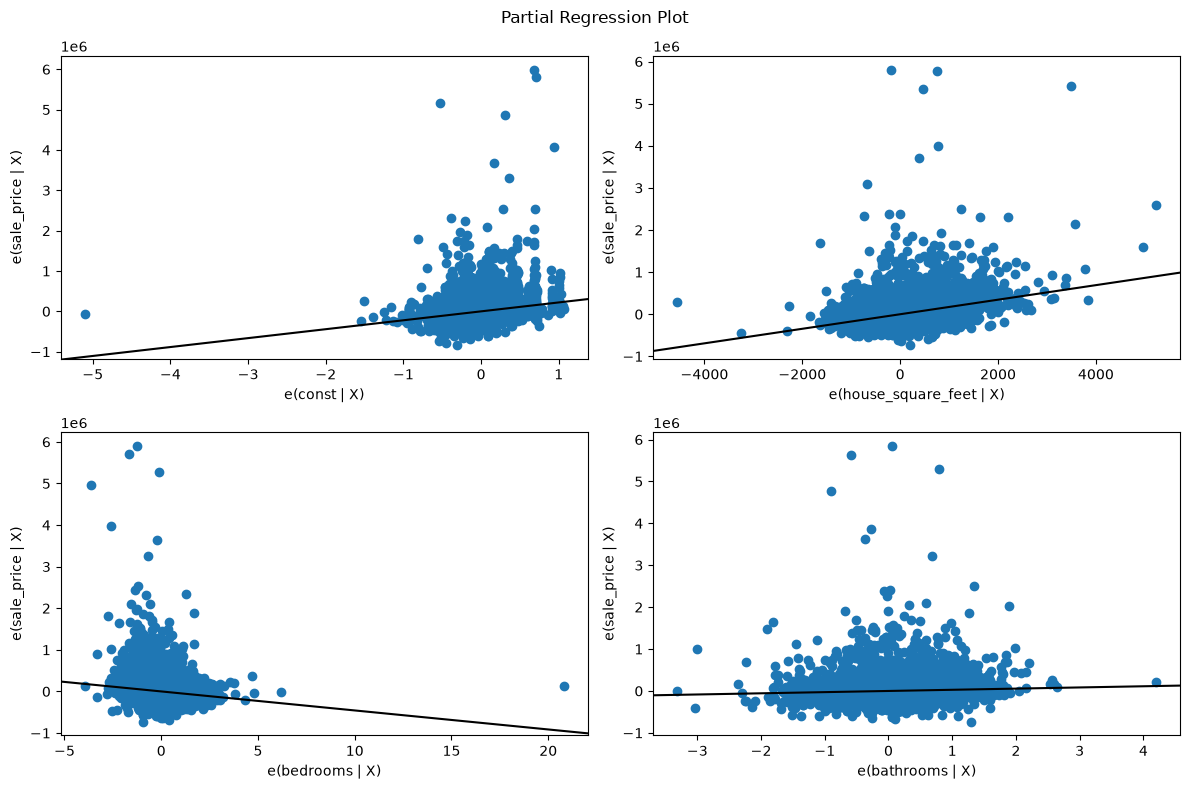

In [17]:
from statsmodels.graphics.regressionplots import plot_partregress_grid
import statsmodels.api as sm

partial_data = df[["sale_price", "house_square_feet", "bedrooms", "bathrooms"]].copy()

model = sm.OLS(partial_data["sale_price"], sm.add_constant(partial_data[["house_square_feet", "bedrooms", "bathrooms"]])).fit()

fig = plt.figure(figsize=(12, 8))
plot_partregress_grid(model, fig=fig)
plt.tight_layout()
plt.show()



Plots don't show any strong non-linearities. There are some outliers, but the relationships between the different variables and sale price are generally linear.

In [18]:
#question 6
df_complex = df.copy()

#nonlinear transformations
df_complex["sqft_squared"] = df_complex["house_square_feet"] ** 2
df_complex["log_sqft"] = np.log1p(df_complex["house_square_feet"])

#interaction terms
df_complex["bed_bath"] = (
    df_complex["bedrooms"] * df_complex["bathrooms"]
)

df_complex["sqft_bath"] = (
    df_complex["house_square_feet"] * df_complex["bathrooms"]
)

# grouping
common_exteriors = ["Frame Siding", "Frame Vinyl",
                    "Masonry Common Brick", "Frame Stucco"]

df_complex["exterior_grouped"] = df_complex["exterior"].where(
    df_complex["exterior"].isin(common_exteriors),
    "Other"
)
df_complex = pd.get_dummies(
    df_complex,
    columns=["exterior_grouped"],
    drop_first=True,
    dtype=int
)

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

features = [
    "house_square_feet",
    "bedrooms",
    "bathrooms",
    "sqft_squared",
    "log_sqft",
    "bed_bath",
    "sqft_bath"
]

#add exterior_grouped columns to the features list
features += [
    col for col in df_complex.columns
    if col.startswith("exterior_grouped_")
]

X = df_complex[features]
y = df_complex["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print("Training RMSE:",
      np.sqrt(mean_squared_error(y_train, train_pred)))

print("Testing RMSE:",
      np.sqrt(mean_squared_error(y_test, test_pred)))

print("Training R²:", r2_score(y_train, train_pred))
print("Testing R²:", r2_score(y_test, test_pred))

Training RMSE: 195794.47314260056
Testing RMSE: 186897.7803193657
Training R²: 0.3106792191640181
Testing R²: 0.32604272273904444


The model that included interactions and transformed variables had a lower train and test R-Squared than the best-performing simple linear model from question 4, indicating that the addition of interactions and transformations had a negative effect on the model's predictive power.

Question 7: The results show that Model 1 performed the best overall, with a training R^2 of 0.367 and a testing R^2 of 0.451. The complex model performed slightly worse, with a training R^2 of 0.342 and a testing R^2 of 0.340. Adding more variables and changes to the regression model did not make it more accurate at predicting house prices. A model that is too simple can underfit the data, and on the other hand a model that is too complex can overfit by capturing patterns that are not applicable to new data. The complex model did not improve performance, so the simpler Model 1 is the optimal choice.

In [19]:
from sklearn.linear_model import Lasso

lasso = Lasso()
lasso.fit(X_train, y_train)

train_pred = lasso.predict(X_train)
test_pred = lasso.predict(X_test)

print("Training RMSE:",
      np.sqrt(mean_squared_error(y_train, train_pred)))

print("Testing RMSE:",
      np.sqrt(mean_squared_error(y_test, test_pred)))

print("Training R²:", r2_score(y_train, train_pred))
print("Testing R²:", r2_score(y_test, test_pred))

lasso_features = [features[i] for i in range(len(features)) if lasso.coef_[i] != 0]
print(f"Selected Lasso Features: {pd.DataFrame(lasso_features)}")


Training RMSE: 191632.50656948585
Testing RMSE: 183364.19653421486
Training R²: 0.3396732744827753
Testing R²: 0.3512861657443592
Selected Lasso Features:                                         0
0                       house_square_feet
1                                bedrooms
2                               bathrooms
3                            sqft_squared
4                                log_sqft
5                                bed_bath
6                               sqft_bath
7           exterior_grouped_Frame Stucco
8            exterior_grouped_Frame Vinyl
9   exterior_grouped_Masonry Common Brick
10                 exterior_grouped_Other


/Users/plee/Documents/UVA/DS3001/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.467310e+14, tolerance: 7.473e+10
  model = cd_fast.enet_coordinate_descent(


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 83da4a449ff3e53836621b2da0511e5ef4d738cc
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. Please analyze responses to questions to verify that they fully answer the question posed. If the question is answered and analysis is just, a suggestion for a change is not necessary.
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Question 4: Add RMSE (training and test) for Models 1, 2 and 3 alongside R², since the question asks for both metrics. The original table reported only R².
2. Question 5: Extend the partial regression plots to all six numeric variables in Model 1 (house_square_feet, bedrooms, bathrooms, stories, year_built, fireplaces). The original plots covered only three, so the conclusion about non-linearity was incomplete.
3. Question 6: Rebuild the complex model on top of Model 1's full feature set, using the same train/test split (random_state = 100), so the comparison to the simple models isolates the effect of the transformations and interactions. The original used different features and a different split.
4. Question 7: Correct the reported complex-model R² values (train 0.311, test 0.326, not 0.342 and 0.340) and revise the overfitting/underfitting discussion to match the results, since test R² was not lower than train R² for any model.
5. Question 8: Standardize the features and select alpha with LassoCV to resolve the ConvergenceWarning. State explicitly which features Lasso keeps or drops, and report RMSE and R².


### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | The question asks for RMSE as well as R², so the table needed to include it. |
| 2 | Accept | Three plots can't support a conclusion about all six numeric variables. |
| 3 | Accept | The changed features and split made the comparison unfair, so the models now share both. |
| 4 | Accept | The R² values in the text did not match the code output, so I corrected them. |
| 5 | Accept | The Lasso did not converge on unscaled features, so scaling and a tuned alpha give more reliable results. |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from statsmodels.graphics.regressionplots import plot_partregress_grid
import statsmodels.api as sm

df = pd.read_csv("data/pierce_county_house_sales.csv")
numeric = ["house_square_feet", "bedrooms", "bathrooms", "stories", "year_built", "fireplaces"]
categorical = ["exterior", "interior", "hvac_description", "roof_cover", "utility_sewer"]
features = numeric + categorical

df = df.dropna(subset=features + ["sale_price"]).copy()
df = df[df["sale_price"] > 0]

y = df["sale_price"]
X = pd.get_dummies(df[features], drop_first=True, dtype=int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=100)

def evaluate(model, Xtr, Xte):
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    return [np.sqrt(mean_squared_error(y_train, p_tr)), np.sqrt(mean_squared_error(y_test, p_te)),
            r2_score(y_train, p_tr), r2_score(y_test, p_te)]

metrics = ["Train RMSE", "Test RMSE", "Train R2", "Test R2"]
num_cols = numeric
cat_cols = [c for c in X.columns if c not in numeric]

m1 = LinearRegression().fit(X_train, y_train)
m2 = LinearRegression().fit(X_train[num_cols], y_train)
m3 = LinearRegression().fit(X_train[cat_cols], y_train)

simple_results = pd.DataFrame({
    "Model 1 (all)": evaluate(m1, X_train, X_test),
    "Model 2 (numeric)": evaluate(m2, X_train[num_cols], X_test[num_cols]),
    "Model 3 (categorical)": evaluate(m3, X_train[cat_cols], X_test[cat_cols])},
    index=metrics)
simple_results


,Model 1 (all),Model 2 (numeric),Model 3 (categorical)
Train RMSE,191302.337351,197495.372009,220833.918473
Test RMSE,153779.706056,154871.552369,189653.850722
Train R2,0.366792,0.325131,0.156204
Test R2,0.450976,0.443152,0.164941


Model 1 (all variables) performs best, with the lowest RMSE and highest R² on both the training and test sets (test RMSE ≈ $153,780, test R² ≈ 0.451). Model 2 (numeric only) is close behind (test RMSE ≈ $154,872, test R² ≈ 0.443), while Model 3 (categorical only) is much worse (test RMSE ≈ $189,654, test R² ≈ 0.165). Most of the predictive power comes from the numeric features.


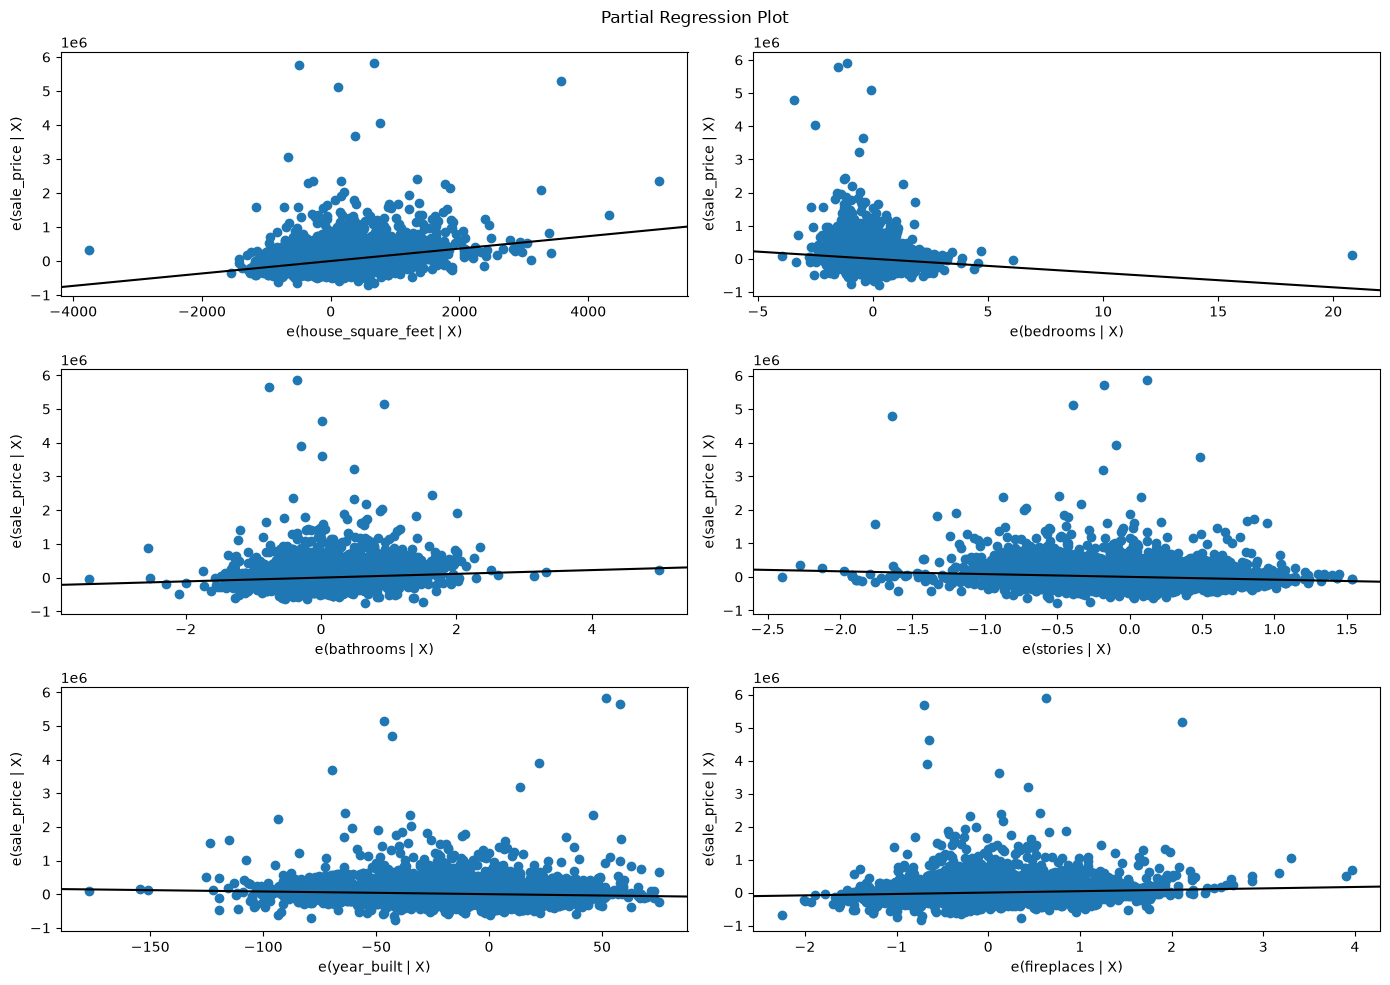

In [21]:
ols = sm.OLS(y, sm.add_constant(df[numeric])).fit()
fig = plt.figure(figsize=(14, 10))
plot_partregress_grid(ols, exog_idx=numeric, fig=fig)
plt.tight_layout()
plt.show()


Across all six numeric variables (square feet, bedrooms, bathrooms, stories, year built, fireplaces), the partial regression plots show no clear curvature, so a straight line is a reasonable approximation. The main departures are a handful of very high-priced outliers (over $4M) and a spread that widens in the middle of the plots (heteroskedasticity), plus one 25-bedroom outlier. These plots only control for the other numeric variables, so they can't rule out non-linearity that the categorical variables would reveal.


In [22]:
dfc = df.copy()

# transformations
dfc["sqft_squared"] = dfc["house_square_feet"] ** 2
dfc["log_sqft"] = np.log1p(dfc["house_square_feet"])
dfc["age"] = 2021 - dfc["year_built"]
dfc["age_squared"] = dfc["age"] ** 2

# interactions
dfc["bed_bath"] = dfc["bedrooms"] * dfc["bathrooms"]
dfc["sqft_bath"] = dfc["house_square_feet"] * dfc["bathrooms"]

# group rare exterior types
common = ["Frame Siding", "Frame Vinyl", "Masonry Common Brick", "Frame Stucco"]
dfc["exterior"] = dfc["exterior"].where(dfc["exterior"].isin(common), "Other")

extra = ["sqft_squared", "log_sqft", "bed_bath", "sqft_bath", "age", "age_squared"]
Xc = pd.get_dummies(dfc[features + extra], drop_first=True, dtype=int).drop(columns=["year_built"])

# same rows as the simple models, so the comparison is fair
Xc_train, Xc_test = Xc.loc[X_train.index], Xc.loc[X_test.index]

mc = LinearRegression().fit(Xc_train, y_train)
all_results = simple_results.copy()
all_results["Complex"] = evaluate(mc, Xc_train, Xc_test)
all_results


,Model 1 (all),Model 2 (numeric),Model 3 (categorical),Complex
Train RMSE,191302.337351,197495.372009,220833.918473,200970.269030
Test RMSE,153779.706056,154871.552369,189653.850722,160533.900008
Train R2,0.366792,0.325131,0.156204,0.301174
Test R2,0.450976,0.443152,0.164941,0.401689


**Q6:** The complex model (Model 1's features plus squared/log square footage, age and age², and bed×bath and sqft×bath interactions) is evaluated on the same split as the simple models. It does not improve on Model 1: test RMSE ≈ $160,534 vs. $153,780, and test R² ≈ 0.402 vs. 0.451. Because the split is identical and the feature base is Model 1's, the added terms (together with swapping year_built for age) did not help. The terms are highly collinear (e.g., sqft, sqft², log sqft), which likely makes the unregularized coefficients unstable.

**Q7:** Model 1 is the best of the unregularized models. For every model, test R² is at or above train R², so none shows clear signs of overfitting. This may be because this particular test split happens to be easier. It also suggests the models are limited by missing information (e.g., location) rather than by variance. The complex model adds flexibility without adding information, so it does not help, and its collinear terms may slightly hurt. The lesson is that more terms do not guarantee better generalization. Model selection should rely on held-out performance, and regularization is a more principled way to add flexibility.


In [23]:
scaler = StandardScaler().fit(Xc_train)
Xs_train, Xs_test = scaler.transform(Xc_train), scaler.transform(Xc_test)

lasso = LassoCV(cv=5, random_state=100, max_iter=100000).fit(Xs_train, y_train)
all_results["Lasso"] = evaluate(lasso, Xs_train, Xs_test)
display(all_results)

coef = pd.Series(lasso.coef_, index=Xc.columns)
print("Chosen alpha:", lasso.alpha_)
print(f"Kept {(coef != 0).sum()} of {len(coef)} features")
print("Dropped:", list(coef[coef == 0].index))
print(coef[coef != 0].sort_values(key=abs, ascending=False).head(10))


,Model 1 (all),Model 2 (numeric),Model 3 (categorical),Complex,Lasso
Train RMSE,191302.337351,197495.372009,220833.918473,200970.269030,190784.860160
Test RMSE,153779.706056,154871.552369,189653.850722,160533.900008,148482.328778
Train R2,0.366792,0.325131,0.156204,0.301174,0.370213
Test R2,0.450976,0.443152,0.164941,0.401689,0.488149


Chosen alpha: 488.34656872326934
Kept 28 of 33 features
Dropped: ['log_sqft', 'bed_bath', 'age', 'hvac_description_Floor Wall Furnace', 'hvac_description_Forced Air']
sqft_squared                            77689.419628
sqft_bath                               35617.959529
bathrooms                               29802.673509
stories                                -27524.904601
bedrooms                               -26240.564884
hvac_description_Heat Pump              23887.005065
fireplaces                              21939.318857
age_squared                             17149.732831
utility_sewer_SEWER/SEPTIC INSTALLED   -16924.940770
utility_sewer_SEWER/SEPTIC NO          -16860.761763
dtype: float64


Lasso (features standardized, alpha chosen by 5-fold cross-validation, alpha ≈ 488) is the best model overall: test RMSE ≈ $148,482 and test R² ≈ 0.488, compared with $153,780 and 0.451 for Model 1. It keeps 28 of 33 features and drops log_sqft, bed_bath, age, and the hvac_description "Floor Wall Furnace" and "Forced Air" dummies. The most influential features are sqft_squared, sqft_bath, bathrooms, stories, and bedrooms. Regularization likely helped by shrinking the collinear terms that hurt the unregularized complex model, which is consistent with its better test fit.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

For this lab, AI was a useful tool for catching simple mistakes that my team and I overlooked in drafting our phase 1 code. For instance, we had compared our models using R-squared, however we had left out the RMSE values that the question requested. Our complex model also used a different split of the data, which made the results harder to compare. Once we used the same split, the differences between models were easier to interpret and draw conclusions from. Beyond that, we were able to improve our Lasso model by standardizing the features and selecting alpha through cross-validation. Verification involved comparing the written conclusions against the code outputs and checking the selected features. However, AI's claim that the results ruled out overfitting was too strong. A remaining concern is that our best model still explained less than half of the variation in testing prices, leaving considerable room for improvement.